In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

C:\Users\potab\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv('NASA TurboFan Engine.csv')
df.head()

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL,Fault_Label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0


In [3]:
df['Fault_Label'].value_counts()

Fault_Label
0    17531
1     3100
Name: count, dtype: int64

In [9]:
df = df.sort_values(['unit', 'cycle']).reset_index(drop = True)

sensor_columns = [col for col in df.columns if col.startswith('sensor')]

In [11]:
split = int(len(X) * 0.8)

train_data = df.iloc[:split].copy()
test_data = df.iloc[split:].copy()

X_train = train_data[sensor_columns]
y_train = train_data['Fault_Label']

X_test = test_data[sensor_columns]
y_test = test_data['Fault_Label']



In [12]:
X_train_normal = X_train[y_train == 0]

In [13]:
scaler = StandardScaler()

scaler.fit(X_train_normal)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (16504, 21)
Testing data shape: (4127, 21)


In [23]:
window_size = 30

def create_windows(df, X, y, window_size):

    X_windows = []
    y_windows = []

    for unit in df['unit'].unique():
        indices = np.where(df['unit'].values == unit)[0]
        unit_X = X[indices]
        unit_y = y.iloc[indices]
        
        for i in range(len(unit_X) - window_size + 1):
            X_windows.append(unit_X[i : i + window_size])
            y_windows.append(np.max(unit_y.iloc[i : i + window_size]))

    return np.array(X_windows), np.array(y_windows)


X_train_windows, y_train_windows = create_windows(
    train_data, X_train_scaled, y_train, window_size
)

X_test_windows, y_test_windows = create_windows(
    test_data, X_test_scaled, y_test, window_size
)

X_train_normal = X_train_windows[y_train_windows == 0]

print("Training windows shape:", X_train_normal.shape)
print("Testing windows shape:", X_test_windows.shape)

Training windows shape: (11615, 30, 21)
Testing windows shape: (3576, 30, 21)


In [26]:
timesteps = X_train_normal.shape[1]
input_dim = X_train_normal.shape[2]

autoencoder = keras.Sequential([
    keras.Input(shape=(timesteps, input_dim)),
    layers.LSTM(32, activation = 'relu', return_sequences = True),
    layers.LSTM(16, activation = 'relu', return_sequences = False),
    layers.RepeatVector(timesteps),
    layers.LSTM(16, activation='relu', return_sequences=True),
    layers.LSTM(32, activation='relu', return_sequences=True),
    layers.TimeDistributed(layers.Dense(input_dim))   
])

In [27]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [28]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs = 11,
    batch_size = 64,
    validation_split = 0.2
)

Epoch 1/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 36s 107ms/step - loss: 0.4795 - mae: 0.4360 - val_loss: 0.3454 - val_mae: 0.3823
Epoch 2/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 18s 87ms/step - loss: 0.3203 - mae: 0.3614 - val_loss: 0.2927 - val_mae: 0.3430
Epoch 3/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - loss: 0.2948 - mae: 0.3397 - val_loss: 0.2823 - val_mae: 0.3325
Epoch 4/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - loss: 0.2896 - mae: 0.3340 - val_loss: 0.2797 - val_mae: 0.3302
Epoch 5/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 21s 86ms/step - loss: 0.2871 - mae: 0.3317 - val_loss: 0.2772 - val_mae: 0.3272
Epoch 6/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - loss: 0.2856 - mae: 0.3304 - val_loss: 0.2766 - val_mae: 0.3273
Epoch 7/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 22s 92ms/step - loss: 0.2842 - mae: 0.3291 - val_loss: 0.2764 - val_mae: 0.3304
Epoch 8/11
146/146 ━━━━━━━━━━━━━━━━━━━━ 14s 97ms/step - loss: 0.2833 - mae: 0.3285 - val_loss: 0.2747 - val_mae: 0.3255
Epoch 9/11
146/146 ━━━━━━━━━━━━━━━━━━━━

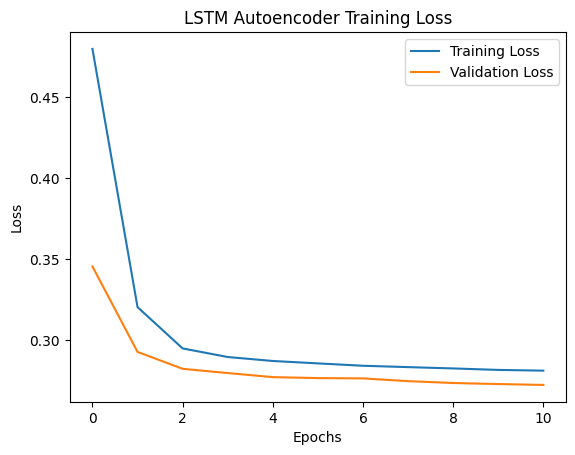

In [29]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [30]:
X_train_pred = autoencoder.predict(X_train_normal)
X_test_pred = autoencoder.predict(X_test_windows)

train_error = np.mean(np.square(X_train_normal - X_train_pred), axis = (1, 2))
test_error = np.mean(np.square(X_test_windows - X_test_pred), axis = (1, 2))

threshold = np.percentile(train_error, 95)
print("Reconstruction Error Threshold:", threshold)

363/363 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step
Reconstruction Error Threshold: 0.46129887453704316


In [31]:
y_pred = (test_error > threshold).astype(int)

print("Predicted classes:")
print(y_pred[:20])

Predicted classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


              precision    recall  f1-score   support

           0       0.85      0.98      0.91      2987
           1       0.57      0.15      0.24       589

    accuracy                           0.84      3576
   macro avg       0.71      0.57      0.58      3576
weighted avg       0.81      0.84      0.80      3576



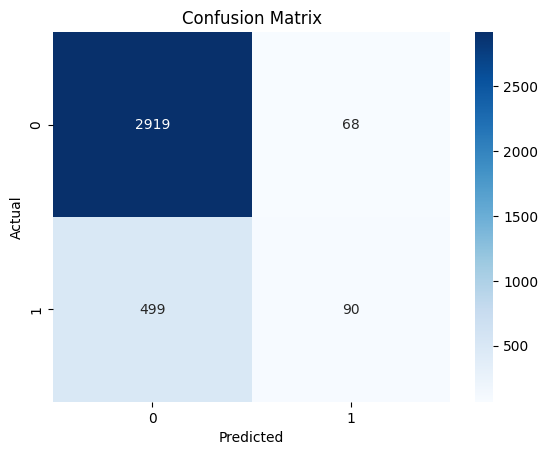

In [32]:
print(classification_report(y_test_windows, y_pred, zero_division = 0))

cm = confusion_matrix(y_test_windows, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()